<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [NetFlow Decoder](https://github.com/Query-farm/vgi-netflow)

Turn captured NetFlow v5/v9, IPFIX, and sFlow v5 datagrams into normalized, queryable flow rows.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-netflow/blob/main/notebooks/02_sample_rows_are_not_packet_counts.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-netflow/blob/main/notebooks/README.md)


## 02 · Sample rows are not packet counts

**Does dropping a counter-sample row reduce the reported traffic?**
Decode one synthetic IPFIX datagram and one synthetic sFlow datagram with their
specialized decoders, then ask the unified decoder to keep all sFlow rows or only
flow samples. Keep returned-row counts, sampled frame length, sampling weight and
normalized traffic counters distinct.

Both files are unchanged golden fixtures generated by the worker's Rust tests.
Their bytes, addresses and counters are authored examples, not captured traffic.
No UDP listener, packet capture or remote collector is used. The example measures
the parser's output semantics; it does not estimate traffic on a real network.

### Choose which sFlow row categories to retain

`SFLOW_MODE="all"` retains the sampled-flow row and the counter-sample row.
The experiment uses `"flows-only"`. The unified `flows` decoder honors this input
column; the specialized `sflow_decode` is a fixed reference and does not use it.
Neither choice changes the original datagram or its sampling weight.

In [1]:
SFLOW_MODE = "all"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.13":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.13"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme, prose
from IPython.display import display, Markdown

check_runtime()
prepare("netflow")
import netflow_example as example

example.validate_mode(SFLOW_MODE)
session = connect(globals())
theme()

### Keep protocol identity beside decoded counters

Attach the public native release and load the two exact fixture files. Read the
protocol version and header first. IPFIX supplies an authored export timestamp;
the sFlow header does not supply an export timestamp, so it remains NULL.
Exporter names are explicit scope labels, not observations about real devices.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL inet FROM core;
LOAD inet;
ATTACH 'netflow' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-netflow@v0.4.0');
CREATE TABLE inputs AS
SELECT 'IPFIX' AS family,'ipfix-demo' AS exporter,content AS datagram FROM read_blob('fixtures/ipfix.dat')
UNION ALL SELECT 'sFlow','sflow-demo',content FROM read_blob('fixtures/sflow.dat');
SELECT family,octet_length(datagram) AS export_payload_bytes,
 netflow.main.flow_version(datagram) AS wire_version,
 (netflow.main.header(datagram)).export_time AT TIME ZONE 'UTC' AS synthetic_export_utc
FROM inputs ORDER BY family;

,family,export_payload_bytes,wire_version,synthetic_export_utc
0,IPFIX,109,10,2023-11-14 22:13:20
1,sFlow,224,sflow5,NaT


### Materialize the two specialized decoders

These functions consume a relation with `datagram` and `exporter` columns; they
are not correlated scalar calls. IPFIX yields its exported byte and packet counters.
sFlow yields a sampling-scaled flow row and a separate counter sample identified
by `diagnostics='counter-sample'`. That label is an informational row category,
not a malformed-datagram error. Unknown flow fields on the counter row remain NULL.

In [5]:
%%sql
CREATE TABLE ipfix_rows AS SELECT * FROM netflow.main.ipfix_decode((SELECT datagram,exporter FROM inputs WHERE family='IPFIX'));
CREATE TABLE sflow_reference AS SELECT * FROM netflow.main.sflow_decode((SELECT datagram,exporter FROM inputs WHERE family='sFlow'));
CREATE TABLE decoded AS SELECT 'IPFIX exported record' AS source_kind,* FROM ipfix_rows
UNION ALL SELECT 'sFlow sample',* FROM sflow_reference;
SELECT source_kind,flow_version,src_addr::INET::VARCHAR AS source_address,
 dst_port,bytes,packets,sampling_rate,diagnostics FROM decoded
ORDER BY source_kind,diagnostics NULLS FIRST;

,source_kind,flow_version,source_address,dst_port,bytes,packets,sampling_rate,diagnostics
0,IPFIX exported record,10,203.0.113.5,443,1500000,1200,<NA>,None
1,sFlow sample,sflow5,192.0.2.10,80,262144,4096,4096,None
2,sFlow sample,sflow5,None,<NA>,<NA>,<NA>,<NA>,counter-sample


In [6]:
ipfix = con.execute("SELECT bytes,packets,sampling_rate FROM ipfix_rows").df().iloc[0]
prose(f"The IPFIX record carries **{int(ipfix.bytes):,} bytes** and **{int(ipfix.packets):,} packets**. Its sampling-rate field is NULL in this fixture; absence of that field is not proof that arbitrary IPFIX data was unsampled. The sFlow values below are constructed with a known weight and require a different interpretation.")

The IPFIX record carries **1,500,000 bytes** and **1,200 packets**. Its sampling-rate field is NULL in this fixture; absence of that field is not proof that arbitrary IPFIX data was unsampled. The sFlow values below are constructed with a known weight and require a different interpretation.

### Change returned row categories without changing the input

Call the unified `flows` decoder on the same sFlow bytes with the selected mode.
Preserve the specialized reference beside it. Materialize explicit categories so
`counter-sample` is neither counted as a flow nor silently treated as a decoding
failure. The mode changes which rows are returned, not the sampled frame's
normalized counters.

In [7]:
%%sql
CREATE TABLE sflow_selected AS SELECT * FROM netflow.main.flows((SELECT datagram,exporter,'{{ SFLOW_MODE }}' AS mode FROM inputs WHERE family='sFlow'));
CREATE TABLE outcomes AS
 SELECT 'Specialized reference' AS scenario,* FROM sflow_reference
 UNION ALL SELECT 'Selected unified scan',* FROM sflow_selected;
CREATE TABLE classified AS SELECT *,
 CASE WHEN diagnostics IS NULL THEN 'Flow sample'
      WHEN diagnostics='counter-sample' THEN 'Counter sample'
      ELSE 'Decode diagnostic' END AS row_kind FROM outcomes;
SELECT scenario,row_kind,bytes,packets,sampling_rate,diagnostics
FROM classified ORDER BY scenario,row_kind;

,scenario,row_kind,bytes,packets,sampling_rate,diagnostics
0,Selected unified scan,Counter sample,<NA>,<NA>,<NA>,counter-sample
1,Selected unified scan,Flow sample,262144,4096,4096,None
2,Specialized reference,Counter sample,<NA>,<NA>,<NA>,counter-sample
3,Specialized reference,Flow sample,262144,4096,4096,None


In [8]:
%%sql populations <<
WITH scenarios AS(SELECT DISTINCT scenario FROM classified),
 kinds AS(SELECT unnest(['Flow sample','Counter sample','Decode diagnostic']) AS row_kind)
SELECT s.scenario,k.row_kind,count(c.row_kind) AS row_count
FROM scenarios s CROSS JOIN kinds k LEFT JOIN classified c USING(scenario,row_kind)
GROUP BY s.scenario,k.row_kind ORDER BY s.scenario,k.row_kind;

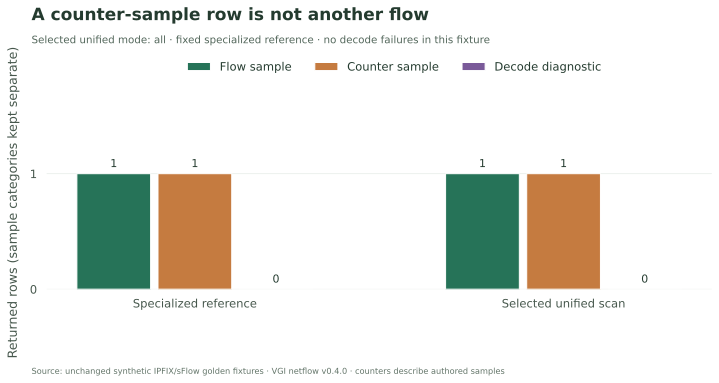

In [9]:
example.row_selection(populations, SFLOW_MODE)

### Reconstruct the sampling arithmetic from returned raw fields

The sFlow decoder preserves the original frame length and sampling weight as
big-endian bytes in `raw_fields`. Decode those integers explicitly in SQL, then
compare their product with the normalized `bytes` field. One sampled frame at
weight 4,096 contributes 4,096 normalized packets. This arithmetic describes the
fixture and decoder; it does not independently validate a sampling design or
measure a complete traffic population.

The IPFIX counter and sFlow estimate share column names but different provenance.
The notebook therefore keeps them separate rather than presenting an unexplained
combined traffic total.

In [10]:
%%sql weights <<
SELECT ('0x'||hex(raw_fields['sflow.frame_length']))::UBIGINT AS raw_frame_bytes,
 ('0x'||hex(raw_fields['sflow.sampling_rate']))::UBIGINT AS raw_weight,
 sampling_rate,bytes AS scaled_bytes,packets AS scaled_packets,
 bytes / sampling_rate AS recovered_frame_bytes
FROM sflow_selected WHERE diagnostics IS NULL;

,raw_frame_bytes,raw_weight,sampling_rate,scaled_bytes,scaled_packets,recovered_frame_bytes
0,64,4096,4096,262144,4096,64.0


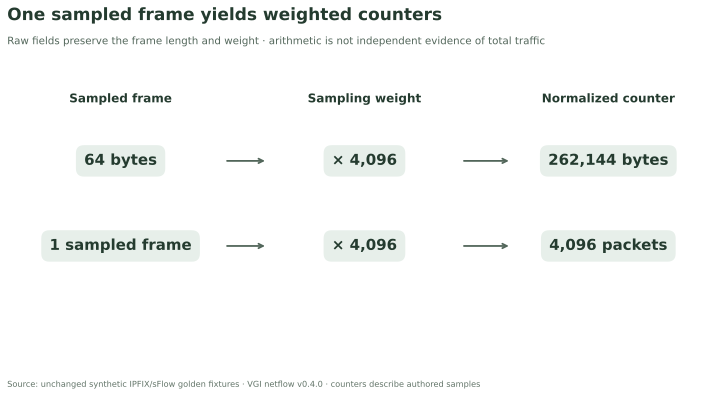

One **64-byte sampled frame** at weight **4,096** yields **262,144 normalized bytes** and **4,096 normalized packets**. These are not the datagram's wire size or the number of output rows. Changing row mode leaves this arithmetic unchanged.

In [11]:
display(weights)
example.sampling_arithmetic(weights)
r = weights.iloc[0]
prose(f"One **{int(r.raw_frame_bytes)}-byte sampled frame** at weight **{int(r.raw_weight):,}** yields **{int(r.scaled_bytes):,} normalized bytes** and **{int(r.scaled_packets):,} normalized packets**. These are not the datagram's wire size or the number of output rows. Changing row mode leaves this arithmetic unchanged.")

### Reconcile the selected rows with their fixed reference

Require exact equality of retained flow records, NULL traffic fields for the
counter sample, unchanged IPFIX controls and the expected sampling relationships.
These checks validate the transformation; they do not establish the coverage,
accuracy or uncertainty of a real flow archive.

In [12]:
%%sql checks <<
SELECT 'Two source datagrams remain fixed' AS check_name,(SELECT count(*)=2 FROM inputs) AS passed
UNION ALL SELECT 'IPFIX produces one clean record',(SELECT count(*)=1 AND bool_and(diagnostics IS NULL) FROM ipfix_rows)
UNION ALL SELECT 'IPFIX fixture counters remain intact',(SELECT bytes=1500000 AND packets=1200 FROM ipfix_rows)
UNION ALL SELECT 'Specialized sFlow retains both categories',(SELECT count(*)=2 AND count(*) FILTER(WHERE diagnostics='counter-sample')=1 FROM sflow_reference)
UNION ALL SELECT 'Selected mode controls counter-row presence',(SELECT count(*) FILTER(WHERE diagnostics='counter-sample')=CASE WHEN '{{ SFLOW_MODE }}'='all' THEN 1 ELSE 0 END FROM sflow_selected)
UNION ALL SELECT 'Selected flow rows equal the fixed reference',(SELECT count(*)=0 FROM((SELECT * FROM sflow_selected WHERE diagnostics IS NULL EXCEPT ALL SELECT * FROM sflow_reference WHERE diagnostics IS NULL) UNION ALL (SELECT * FROM sflow_reference WHERE diagnostics IS NULL EXCEPT ALL SELECT * FROM sflow_selected WHERE diagnostics IS NULL)))
UNION ALL SELECT 'Counter sample keeps traffic fields unknown',(SELECT bool_and(bytes IS NULL AND packets IS NULL AND src_addr IS NULL) FROM sflow_reference WHERE diagnostics='counter-sample')
UNION ALL SELECT 'No decode-error row is present',(SELECT count(*)=0 FROM classified WHERE row_kind='Decode diagnostic')
UNION ALL SELECT 'Normalized bytes equal raw length times weight',(SELECT bool_and(bytes=('0x'||hex(raw_fields['sflow.frame_length']))::UBIGINT * ('0x'||hex(raw_fields['sflow.sampling_rate']))::UBIGINT) FROM sflow_selected WHERE diagnostics IS NULL)
UNION ALL SELECT 'Normalized packet count equals one sample weight',(SELECT bool_and(packets=sampling_rate) FROM sflow_selected WHERE diagnostics IS NULL)
UNION ALL SELECT 'Raw weight equals the projected weight',(SELECT bool_and(sampling_rate=('0x'||hex(raw_fields['sflow.sampling_rate']))::UBIGINT) FROM sflow_selected WHERE diagnostics IS NULL)
UNION ALL SELECT 'sFlow missing timestamps remain unknown',(SELECT bool_and(export_time IS NULL AND flow_start IS NULL AND flow_end IS NULL) FROM sflow_reference);

In [13]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
prose(f"**{len(checks)} checks pass.** Selected flow contents and weighted counters agree with the fixed specialized reference. Row categories, source counter semantics and unavailable fields remain explicit.")

,check_name,passed
0,Two source datagrams remain fixed,True
1,IPFIX produces one clean record,True
2,IPFIX fixture counters remain intact,True
3,Specialized sFlow retains both categories,True
4,Selected mode controls counter-row presence,True
5,Selected flow rows equal the fixed reference,True
6,Counter sample keeps traffic fields unknown,True
7,No decode-error row is present,True
8,Normalized bytes equal raw length times weight,True
9,Normalized packet count equals one sample weight,True


**12 checks pass.** Selected flow contents and weighted counters agree with the fixed specialized reference. Row categories, source counter semantics and unavailable fields remain explicit.

### Keep a separate flows-only experiment

Change `SFLOW_MODE` from **"all"** to **"flows-only"**, restart and run all.
The selected scan should lose one counter-sample row while retaining exactly the
same flow record, bytes, packets and sample weight. The IPFIX control and the
specialized sFlow reference should remain unchanged.

```sh
uv run --locked vgi-notebooks 02_sample_rows_are_not_packet_counts.ipynb --parameters '{"SFLOW_MODE":"flows-only"}' --output-dir artifacts/flows-only
```

Reset to **"all"** afterward. This tiny example does not test estimator bias,
confidence intervals, exporter loss, sampling changes or mixed observation
windows. A port number alone does not identify the application that generated traffic.

In [14]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-netflow](https://github.com/Query-farm/vgi-netflow)